# Single Call Option

## What are we trying to do?

We have sold **one call option on one stock**. At the final date, we must pay the option holder. During the option's life, we buy and sell hedging instruments to help cover that payment.

We compare **four experiments**: the paper-style network and our network, each trading either the stock alone or the stock together with a variance-related instrument.

**This is a small, fresh demonstration.** All four configurations use the training budget below. The displayed results come from these runs, rather than the older three-configuration benchmark. The conclusion is calculated from the results at the end.

**To use this notebook:** put it in your existing project folder, next to `scripts/`. Run the cells from top to bottom. It uses your existing `general_nn.py`, `settings.py`, and revised `plots.py`; it does not redefine the networks. Running the training cell trains all four configurations on the CPU. The saved notebook already contains the example figures and results.

In [1]:
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

from scripts.general_nn import generalNN
from scripts.settings import Settings, InstrumentSettings
from scripts import plots

# Keep the figures sharp, with readable labels.
plt.rcParams.update({"figure.dpi": 500, "font.size": 12, "svg.fonttype": "none"})

# Store the results of this notebook separately from the older benchmark.
RESULTS = Path("results/single_call_option")
FIGURES = RESULTS / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)

# A small training budget. Market parameters and hidden-layer presets are unchanged.
settings = Settings(
    warmup_updates=100,
    continuation_updates=200,
    number_of_replicates=1,
    batch_size=128,
    normalization_size=512,
    validation_size=1024,
    test_size=8192,
    validation_interval=25,
    static_training_size=4096,
)

## 1. What payment do we owe?

The call pays

$$Z=\max(S_T-K,0).$$

$S_T$ is the final stock price, and $K$ is the strike price. Here the initial stock price and strike are both $100$, and the option lasts 30 modeled days. The simulator uses a year fraction of $1/365$ per day.

For example, a final stock price of $90$ gives a payment of $0$. A final stock price of $115$ gives a payment of $15$.

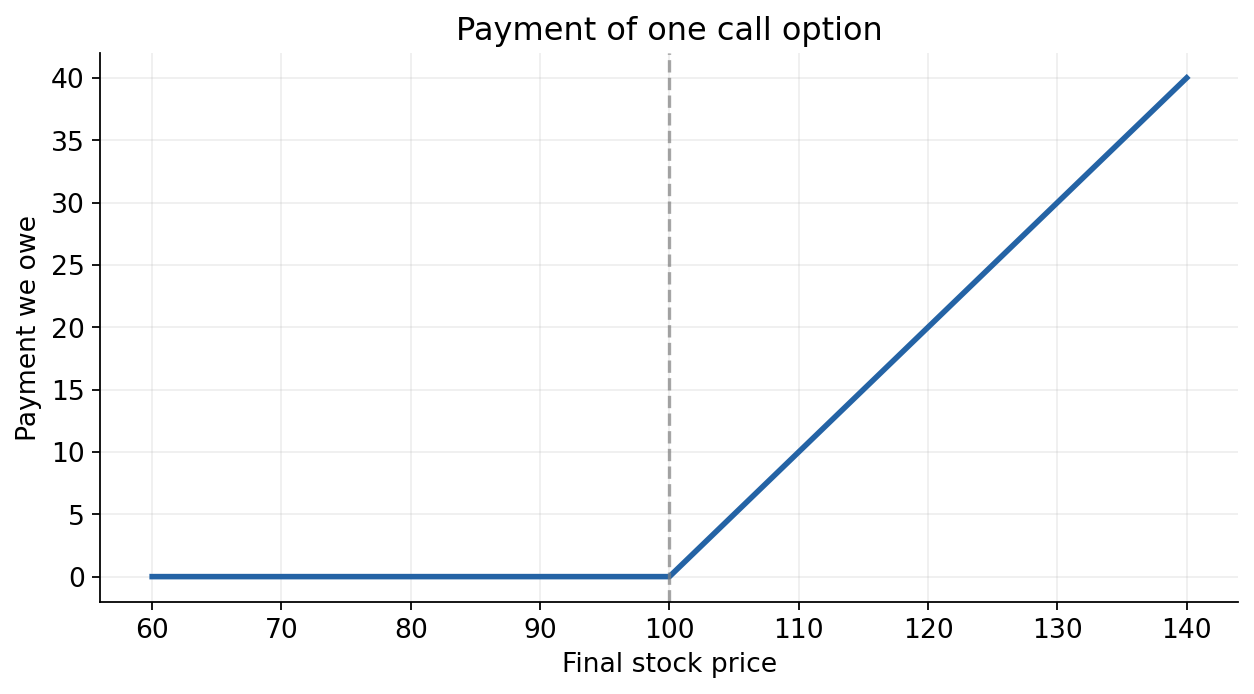

In [2]:
# Draw the amount we owe for different final stock prices.
final_prices = np.linspace(60, 140, 401)
payments = np.maximum(final_prices - settings.strike, 0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(final_prices, payments, linewidth=2.5, color="#2463A5")
ax.axvline(settings.strike, color="gray", linestyle="--", alpha=0.7)
ax.set(title="Payment of one call option", xlabel="Final stock price", ylabel="Payment we owe")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**How to read the graph.** Below the strike, we owe nothing. Above the strike, every additional dollar in the stock price increases our payment by one dollar. This is the liability we hedge; it is not yet the result of a trading strategy.

### How does trading help?

The strategy chooses holdings each day. We measure the remaining loss as

$$L=Z-G_S-G_A+C,$$

where $G_S$ is the gain from trading the stock, $G_A$ is the gain from trading the variance-related instrument, and $C$ is the total transaction cost. In the stock-only experiments, $G_A=0$. The existing accounting function applies each instrument's contract multiplier.

**Lower remaining loss is better.** This loss is measured **before receiving an option premium**. If a common premium $p$ were included, the seller's final profit would be $p-L$. The implementation charges opening and rebalancing costs, with no additional liquidation fee at maturity.

## 2. The four experiments

| Configuration | Network preset | Instruments it can trade | Training data |
|---|---|---|---|
| Paper: stock only | Paper style | Stock | Batches from a fixed pool |
| Paper: stock + variance | Paper style | Stock + variance-related instrument | Batches from a fixed pool |
| Ours: stock only | Ours | Stock | Fresh simulated batches |
| Ours: stock + variance | Ours | Stock + variance-related instrument | Fresh simulated batches |

Variance describes how strongly the stock fluctuates in the model. The additional instrument pays the accumulated variance over the option's life, multiplied by its contract size.

All four observe the **current stock price, current variance, and previous holdings**. They use a separate daily network for each trading date. A stock-only strategy can use variance information even though it cannot trade the variance-related instrument.

The two paper-style configurations retain the existing two hidden layers of width 17, ReLU activations, and batch normalization. The two configurations of ours retain two hidden layers of width 16 and Tanh activations. Adding a tradable instrument to ours expands the input/output sizes using the existing class.

The stock-only paper control keeps its existing output layout and forces its variance holding to zero. For ours with variance, we explicitly supply the two instruments: `trade_variance=True` alone does not add the second instrument to the `ours` preset.

In [3]:
# The variance contract uses the same multiplier as the paper-style configuration.
stock_and_variance = (
    InstrumentSettings(name="Stock", kind="stock", stock_index=0),
    InstrumentSettings(
        name="Stock variance", kind="variance", stock_index=0,
        multiplier=settings.variance_notional,
    ),
)

# Paper-style network, restricted to stock trading.
paper_stock = generalNN(
    method="paper", settings=replace(settings, trade_variance=False),
    dynamic_data=False, name="Paper: stock only",
)

# Paper-style network, with both trading instruments.
paper_variance = generalNN(
    method="paper", settings=replace(settings, trade_variance=True),
    dynamic_data=False, name="Paper: stock + variance",
)

# Our network, trading only the stock.
ours_stock = generalNN(
    method="ours", settings=settings,
    dynamic_data=True, name="Ours: stock only",
)

# Our network, with both trading instruments explicitly configured.
ours_variance = generalNN(
    method="ours", settings=replace(settings, instruments=stock_and_variance),
    dynamic_data=True, name="Ours: stock + variance",
)

experiments = [paper_stock, paper_variance, ours_stock, ours_variance]
save_names = ["paper_stock", "paper_variance", "ours_stock", "ours_variance"]

# Check the trading opportunities that the settings actually created.
display(pd.DataFrame([
    {"Configuration": e.name,
     "Can trade": ", ".join(i.name for i in e.settings.instruments if i.tradable),
     "Training data": "Fresh batches" if e.dynamic_data else "Fixed pool"}
    for e in experiments
]))

,Configuration,Can trade,Training data
0,Paper: stock only,Stock,Fixed pool
1,Paper: stock + variance,"Stock, Stock variance",Fixed pool
2,Ours: stock only,Stock,Fresh batches
3,Ours: stock + variance,"Stock, Stock variance",Fresh batches


## 3. What does "better" mean?

We train a separate strategy for each of two risk criteria.

**CVaR:** focus on the worst part of the loss distribution. With $\alpha=0.5$, the empirical score is the average of the worst half of the test losses (with fractional weighting at a boundary when needed). The general definition is

$$\operatorname{CVaR}_{\alpha}(L)=\min_m\left\{m+\frac{\mathbb{E}[(L-m)_+]}{1-\alpha}\right\}.$$

**Entropic risk:** give exponentially greater weight to large losses. Here $\lambda=1$:

$$\rho_{\lambda}(L)=\frac{1}{\lambda}\log\mathbb{E}[e^{\lambda L}].$$

We estimate these quantities on simulated paths. Lower is better for either criterion. Compare the four CVaR-trained strategies using CVaR, and the four entropic-trained strategies using entropic risk. Their numerical values answer different questions.

There are **four configurations and eight final policies**: one CVaR policy and one entropic policy for each configuration.

## 4. Train, then evaluate on new scenarios

Each configuration first receives **100 CVaR warm-up updates**. We copy the selected warm-up policy and train two separate branches: **200 more updates for CVaR** and **200 for entropic risk**. This is 500 optimizer updates per configuration.

Validation uses 1,024 fixed scenarios to select a checkpoint. Final evaluation uses 8,192 separate test scenarios. The same seeds and market settings give all four configurations matching underlying validation and test scenarios. The two paper configurations use the same fixed training pool of 4,096 paths; ours generates batches during training.

The market remains the project's Heston simulation, with 30 trading dates, 64 simulation substeps per day, and proportional transaction costs of 0.001. These are **short demonstration runs**, with one initialization per configuration.

In [4]:
# Train and save each experiment in its own folder.
# Run the constructor cell again before repeating fresh training.
for folder_name, experiment in zip(save_names, experiments):
    print(f"\nTraining {experiment.name}", flush=True)
    experiment.train(objectives=("CVaR", "Entropic"), verbose=True)
    experiment.evaluate()
    experiment.save(RESULTS / folder_name)

# Verify that the four methods were tested on exactly the same market scenarios.
reference_test = experiments[0].data["test"]
for experiment in experiments[1:]:
    test = experiment.data["test"]
    for field in ("stock_prices", "variances", "payoffs"):
        assert torch.equal(getattr(reference_test, field), getattr(test, field))

print(f"\nAll four configurations use the same {len(reference_test):,} test scenarios.")


Training Paper: stock only
paper_stock_0_warmup: update 0, validation risk 5.37687
paper_stock_0_warmup: update 100, validation risk 3.11939
paper_stock_0_CVaR: update 0, validation risk 3.13262
paper_stock_0_CVaR: update 200, validation risk 3.06056
paper_stock_0_Entropic: update 0, validation risk 13.73358
paper_stock_0_Entropic: update 200, validation risk 15.20458

Training Paper: stock + variance
paper_full_0_warmup: update 0, validation risk 6.75343
paper_full_0_warmup: update 100, validation risk 2.79128
paper_full_0_CVaR: update 0, validation risk 2.80778
paper_full_0_CVaR: update 200, validation risk 2.64514
paper_full_0_Entropic: update 0, validation risk 6.26713
paper_full_0_Entropic: update 200, validation risk 2.49238

Training Ours: stock only
ours_0_warmup: update 0, validation risk 4.16716
ours_0_warmup: update 100, validation risk 2.87125
ours_0_CVaR: update 0, validation risk 2.82243
ours_0_CVaR: update 200, validation risk 2.82405
ours_0_Entropic: update 0, validati

The test scenarios measure performance after training; they do not choose the weights. Each configuration was trained for both objectives, and every comparison below uses these shared test scenarios.

To reopen these runs later without training again, replace the training cell with:

```python
experiments = [generalNN.load(RESULTS / name) for name in save_names]
```

Continue from the results cell below. Its calculations use `experiments`, so they also work after loading.

## 5. The measured results

Each row represents one trained policy from run 0, the single run configured in this notebook. **Test risk** uses the objective named in that row. **Mean cost is already included in the loss and risk**; do not add it again. The largest loss is the largest observation in this finite test sample, not a worst-case bound.

In [5]:
# Collect the stored measurements; this does not train the networks again.
rows = []
for experiment in experiments:
    for objective in ("CVaR", "Entropic"):
        run = experiment.get_run(objective, replicate=0)
        metrics = run["metrics"]
        rows.append({
            "Configuration": experiment.name,
            "Objective": objective,
            "Test risk": metrics[objective.lower()],
            "Mean loss": metrics["mean_loss"],
            "Mean cost": metrics["mean_cost"],
            "Largest loss": metrics["max_loss"],
        })

results = pd.DataFrame(rows)
display(results.round(4))
results.to_csv(RESULTS / "comparison.csv", index=False)

,Configuration,Objective,Test risk,Mean loss,Mean cost,Largest loss
0,Paper: stock only,CVaR,3.0270,1.9252,0.2747,33.0536
1,Paper: stock only,Entropic,16.7343,1.9982,0.3317,24.9313
2,Paper: stock + variance,CVaR,2.6681,1.9282,0.2738,29.7490
3,Paper: stock + variance,Entropic,4.2965,1.9485,0.2635,11.5163
4,Ours: stock only,CVaR,2.7829,1.8347,0.1704,15.8008
5,Ours: stock only,Entropic,3.9828,1.8136,0.1373,11.6451
6,Ours: stock + variance,CVaR,2.3372,1.8780,0.1841,9.4613
7,Ours: stock + variance,Entropic,2.1116,1.8366,0.1386,6.0731


## 6. Which configuration has lower measured risk?

The next two figures compare all four configurations and a **no-hedge** reference. The no-hedge loss is just the call payment. In this notebook there is one training run, so each configuration's dot and mean marker coincide.

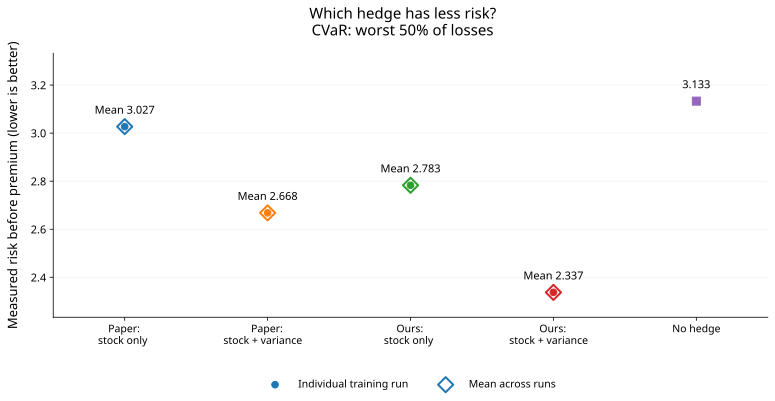

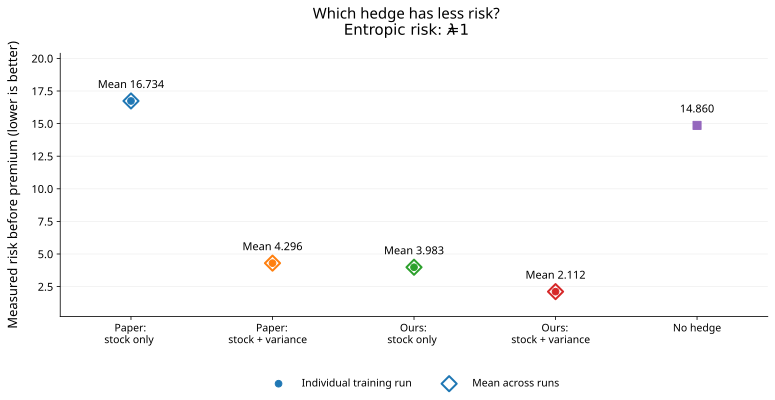

In [6]:
# One full-size figure per objective, using the existing plotting module.
plots.plot_risk(experiments, figsize=(11, 6), save_dir=FIGURES)

**How to read these graphs.** Lower points indicate lower risk on the common test sample. Compare **paper stock only with ours stock only**, and **paper stock + variance with ours stock + variance**, to compare the approaches with equal trading opportunities. Compare the two configurations within each approach to see what adding the variance instrument changed. These points are not confidence intervals.

## 7. What happened during training?

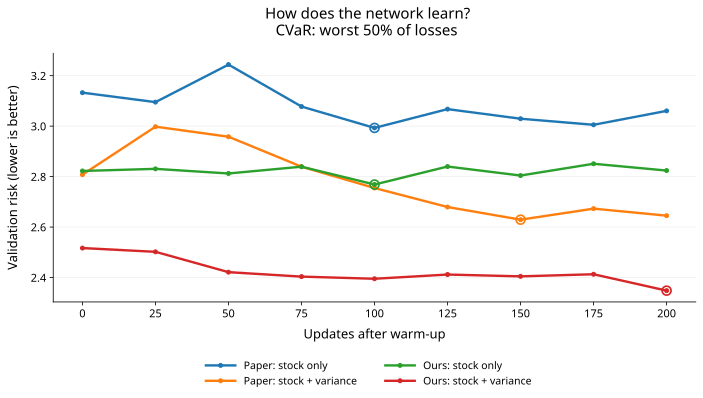

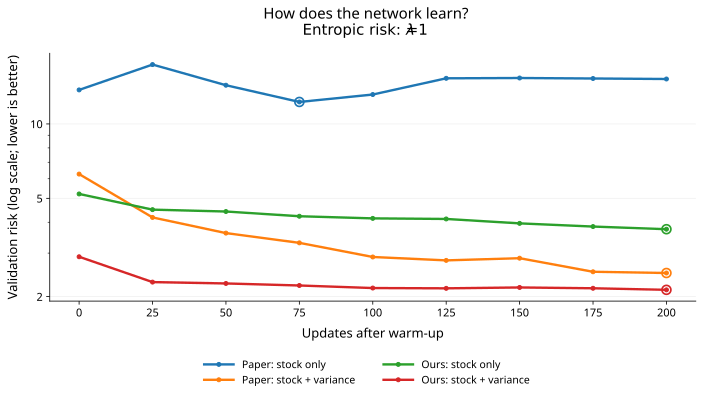

In [7]:
# Show the validation scores after each configuration's CVaR warm-up.
plots.plot_learning(experiments, replicate=0, figsize=(10, 6), save_dir=FIGURES)

**How to read these graphs.** The horizontal axis counts optimizer updates after warm-up, not market days. An open circle marks the checkpoint selected using validation. A curve can fall and then rise because an update that improves a training batch need not improve validation. Straight lines connect recorded checkpoints; no smoothing is applied. A dip is a better recorded validation score, not a fall in the stock price.

## 8. Why can a few bad hedges matter so much?

Average loss alone can hide rare large losses. The next graphs show the percentage of test scenarios whose losses reach each threshold. We show both objectives, with particular attention to the entropic-trained policies.

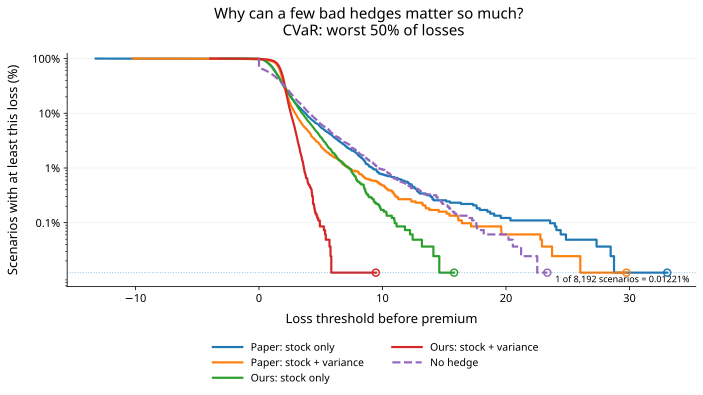

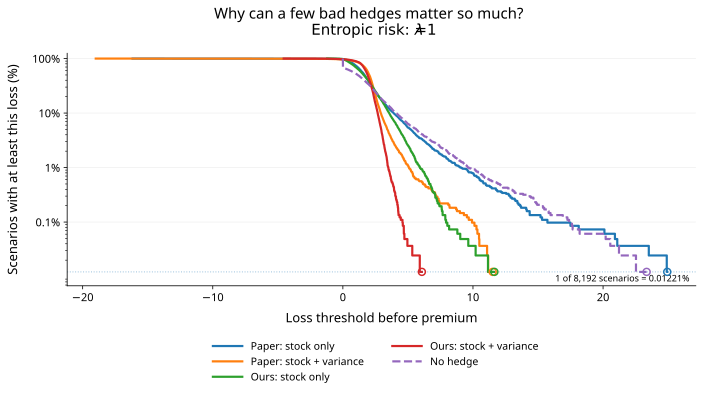

In [8]:
# Keep every observed extreme loss, with a logarithmic percentage axis.
plots.plot_loss_tails(
    experiments, threshold=None, replicate=0, figsize=(10, 6), save_dir=FIGURES,
)

**How to read these graphs.** Choose a loss threshold on the horizontal axis. The vertical value is the percentage of scenarios with loss at least that large. A lower curve at that threshold means fewer exceedances. The vertical scale is logarithmic: moving from 1% to 0.1% means ten times fewer scenarios. The endpoint circle marks the largest observed loss; the dotted horizontal line corresponds to one test scenario.

These curves show ordinary scenario frequencies. Entropic risk then gives large-loss scenarios much more weight through the exponential. A far-right observation can therefore have a large effect even when it occurs only once.

## 9. Direct comparisons and conclusion

The table below subtracts two risk scores. **A positive number supports the improvement named in the row; a negative number means the opposite happened.** All differences are absolute risk units, separately for CVaR and entropic risk.

In [9]:
risk_table = results.pivot(index="Configuration", columns="Objective", values="Test risk")

# Each pair gives the first risk minus the second risk.
comparisons = {
    "Benefit of variance trading: paper": ("Paper: stock only", "Paper: stock + variance"),
    "Benefit of variance trading: ours": ("Ours: stock only", "Ours: stock + variance"),
    "Our advantage: stock only": ("Paper: stock only", "Ours: stock only"),
    "Our advantage: stock + variance": ("Paper: stock + variance", "Ours: stock + variance"),
}

differences = pd.DataFrame({
    label: risk_table.loc[first] - risk_table.loc[second]
    for label, (first, second) in comparisons.items()
}).T
display(differences.round(4))
differences.to_csv(RESULTS / "risk_differences.csv")

# Write the numerical conclusion from this run, so it updates after rerunning.
paragraphs = ["### What this run shows"]
for objective in ("CVaR", "Entropic"):
    scores = risk_table[objective]
    winner = scores.idxmin()
    text = f"**{objective}.** Among the four trained configurations, the lowest measured risk was **{scores[winner]:.4f}**, achieved by **{winner}**. "
    for label in ("Paper", "Ours"):
        approach = "the paper-style approach" if label == "Paper" else "our approach"
        stock = scores[f"{label}: stock only"]
        variance = scores[f"{label}: stock + variance"]
        change = stock - variance
        direction = "lowered" if change > 0 else "raised" if change < 0 else "did not change"
        if change == 0:
            text += f"Adding variance trading did not change measured risk for {approach} ({stock:.4f}). "
        else:
            text += f"Adding variance trading {direction} measured risk for {approach} from {stock:.4f} to {variance:.4f}, a change of {abs(change):.4f}. "
    baseline = experiments[0].benchmarks["no_hedge"][objective.lower()]
    text += f"The no-hedge reference had risk {baseline:.4f}. "
    worse = scores[scores > baseline].index.tolist()
    if worse:
        text += f"{'; '.join(worse)} had higher risk than no hedge in this run."
    paragraphs.append(text)

display(Markdown("\n\n".join(paragraphs)))

Objective,CVaR,Entropic
Benefit of variance trading: paper,0.3589,12.4379
Benefit of variance trading: ours,0.4457,1.8712
Our advantage: stock only,0.2441,12.7515
Our advantage: stock + variance,0.3309,2.1848


### What this run shows

**CVaR.** Among the four trained configurations, the lowest measured risk was **2.3372**, achieved by **Ours: stock + variance**. Adding variance trading lowered measured risk for the paper-style approach from 3.0270 to 2.6681, a change of 0.3589. Adding variance trading lowered measured risk for our approach from 2.7829 to 2.3372, a change of 0.4457. The no-hedge reference had risk 3.1332. 

**Entropic.** Among the four trained configurations, the lowest measured risk was **2.1116**, achieved by **Ours: stock + variance**. Adding variance trading lowered measured risk for the paper-style approach from 16.7343 to 4.2965, a change of 12.4379. Adding variance trading lowered measured risk for our approach from 3.9828 to 2.1116, a change of 1.8712. The no-hedge reference had risk 14.8602. Paper: stock only had higher risk than no hedge in this run.

### What can we conclude?

The four configurations answer two separate questions: **how the approaches compare with the same available instruments**, and **what changes when each approach can also trade the variance-related instrument**. The measured changes are reported above; an additional instrument need not improve the result of a short optimization run.

Treat these as **preliminary numerical findings**, not a general ranking. We used one initialization and a small training budget. The paper-style configurations use a fixed pool while ours uses fresh batches, so an across-approach difference combines network-design and data-supply effects. Repeated initializations and a larger evaluation sample would be needed to judge how stable the differences are. A finite simulated entropic score also does not establish that the population exponential moment is finite.

This is a benchmark for hedging **one fixed call liability**. It prepares the larger portfolio-compression project; these four runs by themselves do not establish a benefit from compressing a portfolio description.

### Source and reproducibility

The network, simulation, training, and accounting code come from the current project:

- [general_nn.py](https://github.com/AlpayNatanael/Deep-Hedging-Implementation/blob/6194779bb1c6dc869899b11dbad0014cc75459ff/scripts/general_nn.py)
- [settings.py](https://github.com/AlpayNatanael/Deep-Hedging-Implementation/blob/6194779bb1c6dc869899b11dbad0014cc75459ff/scripts/settings.py)
- [plots.py](https://github.com/AlpayNatanael/Deep-Hedging-Implementation/blob/6194779bb1c6dc869899b11dbad0014cc75459ff/scripts/plots.py)

The current repository version fixes the extra quotation mark in the previously annotated `_generate()` docstring. Use that working project version to run this notebook. "Paper style" names the implementation's preset; these small runs are not a claim of reproducing every experiment in the published paper.

The saved models, comparison tables, and high-resolution figures are written under `results/single_call_option/` when you run the notebook. Results can differ with changes to the project files, package versions, seeds, or numerical environment.